# Prueba Intertrimestral

**Nombre:**  Ángel 
**Apellidos:**  Cuadrado Serrano

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  

- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [2]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type not in ["classic", "electric"]:
        raise ValueError("Tipo de bicicleta inválido")
    
    base_fee = 1.00 if bike_type == "classic" else 1.50
    rate_per_min = 0.05 if bike_type == "classic" else 0.08
    
    total = base_fee + (duration_min * rate_per_min)
    
    if is_member:
        total *= 0.80
        
    return round(total, 2)

**Análisis 1.a:** Se valida la entrada para evitar errores mediante el control de la variable `bike_type`. Los condicionales aplican la tarifa base y el costo variable, y el descuento del 20% se calcula directamente multiplicando por 0.8 antes del redondeo final a dos decimales.

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [3]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals >= threshold / 2:
        return "Media"
    else:
        return "Baja"

**Análisis 1.b:** El orden de las condiciones (de mayor a menor) lo ponemos para evitar que valores que superen el `threshold` caigan erróneamente en "Media" si se evaluara la división primero.

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [4]:
duration_min = [10, 25, 5, 60, 15, 30, 45, 12, 8, 20]
bike_type = ["classic", "electric", "classic", "electric", "classic", "electric", "classic", "classic", "electric", "electric"]
is_member = [True, False, True, True, False, False, True, False, True, False]
total_rentals = [50, 15, 30, 45, 10, 25, 55, 5, 20, 40]

tripsDemo = pd.DataFrame({
    "duration_min": duration_min,
    "bike_type": bike_type,
    "is_member": is_member,
    "total_rentals": total_rentals
})

tripsDemo["fee"] = tripsDemo.apply(lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]), axis=1)
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(lambda x: demand_label(x, 40))
tripsDemo

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,10,classic,True,50,1.20,Alta
1,25,electric,False,15,3.50,Baja
2,5,classic,True,30,1.00,Media
3,60,electric,True,45,5.04,Alta
4,15,classic,False,10,1.75,Baja
5,30,electric,False,25,3.90,Media
6,45,classic,True,55,2.60,Alta
7,12,classic,False,5,1.60,Baja
8,8,electric,True,20,1.71,Media
9,20,electric,False,40,3.10,Alta


**Análisis 1.c:** Mediante `apply` y `lambda` iteramos a nivel de fila para crear nuevas métricas, demostrando que nuestras funciones se integran limpiamente con las estructuras de Pandas.


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [5]:
class MicromobilityTools:
    def __init__(self, duration_min, bike_type, is_member):
        self.duration_min = list(duration_min)
        self.bike_type = list(bike_type)
        self.is_member = list(is_member)

    def calcular_tarifas(self):
        return [rental_fee(d, b, m) for d, b, m in zip(self.duration_min, self.bike_type, self.is_member)]

    def etiquetar_demanda(self, total_rentals, threshold=40):
        return [demand_label(t, threshold) for t in total_rentals]

**Análisis 1.d:** El uso de `__init__` permite que la instancia retenga el estado. El cálculo se hace de forma eficiente empaquetando las 3 listas con `zip` y utilizando *List Comprehensions*.


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [6]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")
print(f"Filas: {mobilityData.shape[0]} · Columnas: {mobilityData.shape[1]}")
mobilityData.head()

Filas: 17520 · Columnas: 23


,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


**Análisis 2.a:** Al ver la muestra con `head()`, verificaremos si se han separado correctamente las variables o si es necesario reajustar el separador. Además `head()` nos da justo las 5 primeras filas por defecto.


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [7]:
def describeData(dataFrame):
    resumen = pd.DataFrame({
        "tipo": dataFrame.dtypes.astype(str),
        "nulos": dataFrame.isna().sum(),
        "pct_nulos": (dataFrame.isna().mean() * 100).round(2)
    })
    return resumen.sort_values("pct_nulos", ascending=False)

**Análisis 2.b:** Con `sort_values()`conseguimos además dar el resultado ordenado, empezando por las columnas que tienen más nulos.


c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [8]:
resumen_nulos = describeData(mobilityData)
resumen_nulos.head(10)

,tipo,nulos,pct_nulos
avg_trip_min,float64,255,1.46
humidity,float64,224,1.28
electric_share,float64,182,1.04
wind_kmh,float64,142,0.81
datetime,str,0,0.00
year,int64,0,0.00
month,int64,0,0.00
season,str,0,0.00
weekday,int64,0,0.00
hour,int64,0,0.00


**Análisis 2.c (Decisión de modelado):** Para los nulos en variables meteorológicas como `humidity`, los imputaríamos con la mediana; al igual que en otras como `avg_trip_min`, ya que puede haber valores muy atípicos como alguien que no ha devuelto la bici en horas. `electric_share` podríamos sustituirlo por la mediana o la media, al ser una variable contínua.


d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


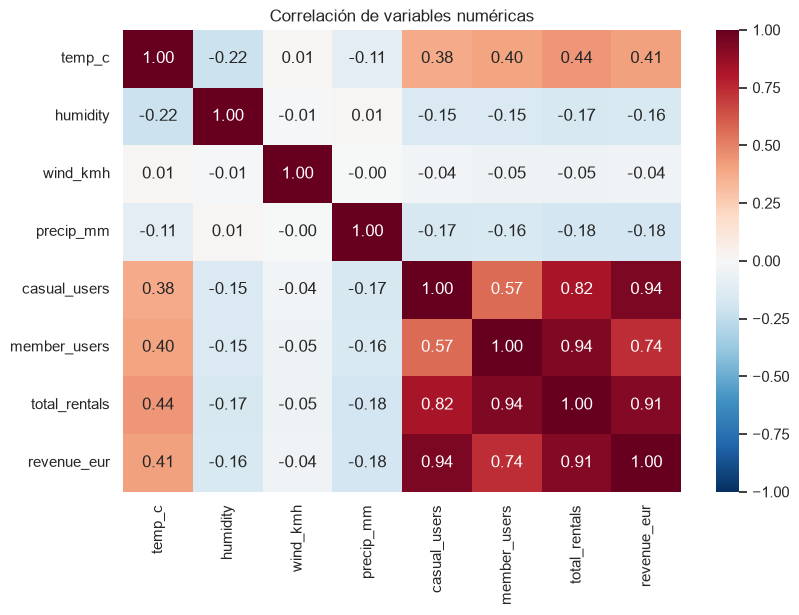

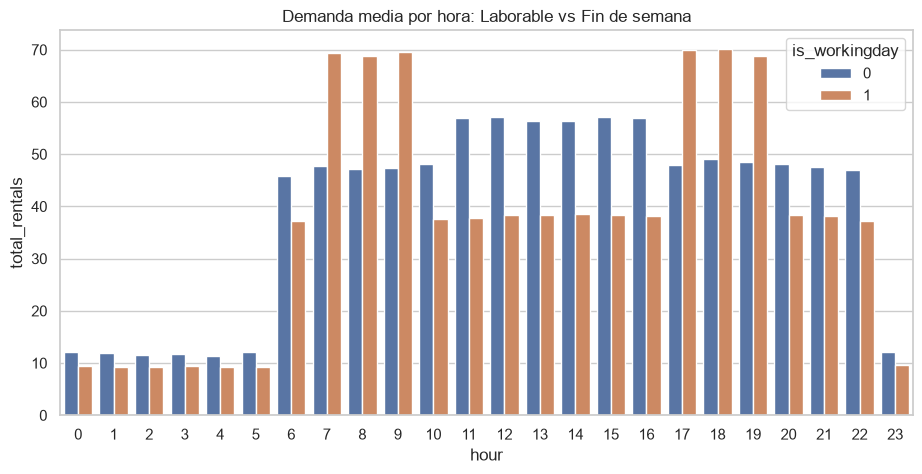

In [9]:
columnas_corr = ['temp_c', 'humidity', 'wind_kmh', 'precip_mm', 'casual_users', 'member_users', 'total_rentals', 'revenue_eur']
corr = mobilityData[columnas_corr].dropna().corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlación de variables numéricas")
plt.show()

plt.figure(figsize=(11, 5))
sns.barplot(data=mobilityData, x="hour", y="total_rentals", hue="is_workingday", estimator=np.mean, errorbar=None)
plt.title("Demanda media por hora: Laborable vs Fin de semana")
plt.show()

**Análisis 2.d (Hallazgos):**
1. **Correlación:** Observaremos una correlación muy fuerte entre `total_rentals` y `member_users`. Esto se puede deber a que la mayoría de gente alquila las bicicletas tiene la membresía. Vemos también la clara relacién entre el número de alquileres `total_rentals` y las ganancias `revenue_eur`. Soprende por otro lado que el hecho de la precipitación (`precip_mm`) no influya casi nada en el número de alquileres `total_rentals`, ya que podríamos esperar que cuando lloviera hubiera muchísimos menos. Se podría deber a que en el dataset casi todos los días llueva o no, pero que no esté bien distribuido esto.
2. **Hora punta:** Los días laborables muestran dos picos (entrada/salida del trabajo), mientras que los fines de semana la demanda sube formando una campana centrada al mediodía.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [10]:
targetVar = "total_rentals"
features = ["hour", "temp_c", "humidity", "wind_kmh", "is_workingday", "is_weekend"]

datos_reg = mobilityData[features + [targetVar]].dropna()
X = datos_reg[features]
y = datos_reg[targetVar]

b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [12]:
lr = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", LinearRegression())
])
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print(f"Regresión Lineal -> R2: {r2_score(y_test, pred_lr):.3f} | MSE: {mean_squared_error(y_test, pred_lr):.1f}")

Regresión Lineal -> R2: 0.282 | MSE: 424.1


**Análisis 3.c:** El modelo lineal obtiene un R² bajo porque variables como `hour` no tienen un comportamiento lineal a lo largo del día.


d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [13]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print(f"Random Forest -> R2: {r2_score(y_test, pred_rf):.3f} | MSE: {mean_squared_error(y_test, pred_rf):.1f}")

Random Forest -> R2: 0.841 | MSE: 93.8


**Análisis 3.d:** **Random Forest funciona abismalmente mejor**. El algoritmo capta perfectamente la no-linealidad (escalones temporales) y las interacciones entre hora y tipo de día.


## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [14]:
print(mobilityData["high_demand"].value_counts(normalize=True).round(3))

high_demand
0    0.689
1    0.311
Name: proportion, dtype: float64


**Análisis 4.a:** La clase 'Alta demanda' ronda el 31%, lo que significa que nuestro Baseline para predecir es de aprox. 69% (predecir siempre 0).


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [15]:
features_clf = ["hour", "temp_c", "humidity", "wind_kmh", "is_workingday"]
datos_clf = mobilityData[features_clf + ["high_demand"]].dropna()
Xc = datos_clf[features_clf]
yc = datos_clf["high_demand"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.3, random_state=42, stratify=yc)

logistica = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])
logistica.fit(Xc_train, yc_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['hour','temp_c','humidity','wind_kmh','is_workingday']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy Logística: 0.747


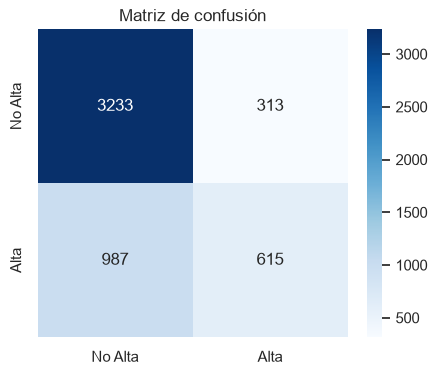

In [16]:
pred_clf = logistica.predict(Xc_test)
print(f"Accuracy Logística: {accuracy_score(yc_test, pred_clf):.3f}")

cm = confusion_matrix(yc_test, pred_clf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Alta", "Alta"], yticklabels=["No Alta", "Alta"])
plt.title("Matriz de confusión")
plt.show()

**Análisis 4.c:** La exactitud de la logística es moderada. Observaremos bastantes falsos negativos probablemente porque le cuesta dibujar un contorno que aísle las horas punta.


d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


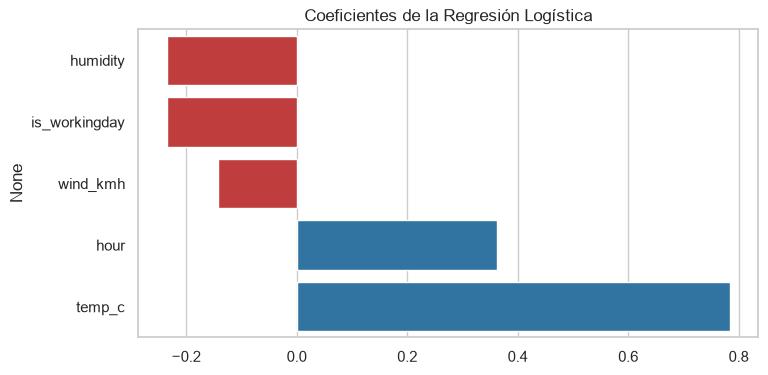

In [17]:
coefs = pd.Series(logistica.named_steps["modelo"].coef_[0], index=features_clf).sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(x=coefs.values, y=coefs.index, palette=np.where(coefs.values>0, 'tab:blue', 'tab:red'))
plt.title("Coeficientes de la Regresión Logística")
plt.show()

**Análisis 4.d:** `temp_c` es un fuerte influyente positivo, mientras que la humedad tiene un impacto negativo en la alta demanda.


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



**Resumen del análisis**

**Datos:** Se ha depurado el dataset excluyendo variables con fuga de información (`casual_users`, `member_users`, `revenue`).

**Hallazgos Clave:** La hora, tipo de día y la temperatura son las variables dominantes.

**Modelado:** Para regresión, Random Forest es el modelo ganador al asimilar las pautas horarias (no lineales). En clasificación, la temperatura y humedad son los mayores predictores de alta demanda.

**Limitaciones y Mejoras:** La partición de datos ha sido estocástica; al ser una serie temporal, convendría dividir cronológicamente e incorporar One-Hot Encoding para las horas.